<>:38: SyntaxWarning: invalid escape sequence '\e'
<>:38: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_3252/631997677.py:38: SyntaxWarning: invalid escape sequence '\e'
  label=f"Noisy $s(k)$ ($\eta$={eta})",color="red",lw=0.8,alpha=0.7,)


 
Standard Deviation Clean Signal 0.334
Standard Deviation Noisy Signal 0.033


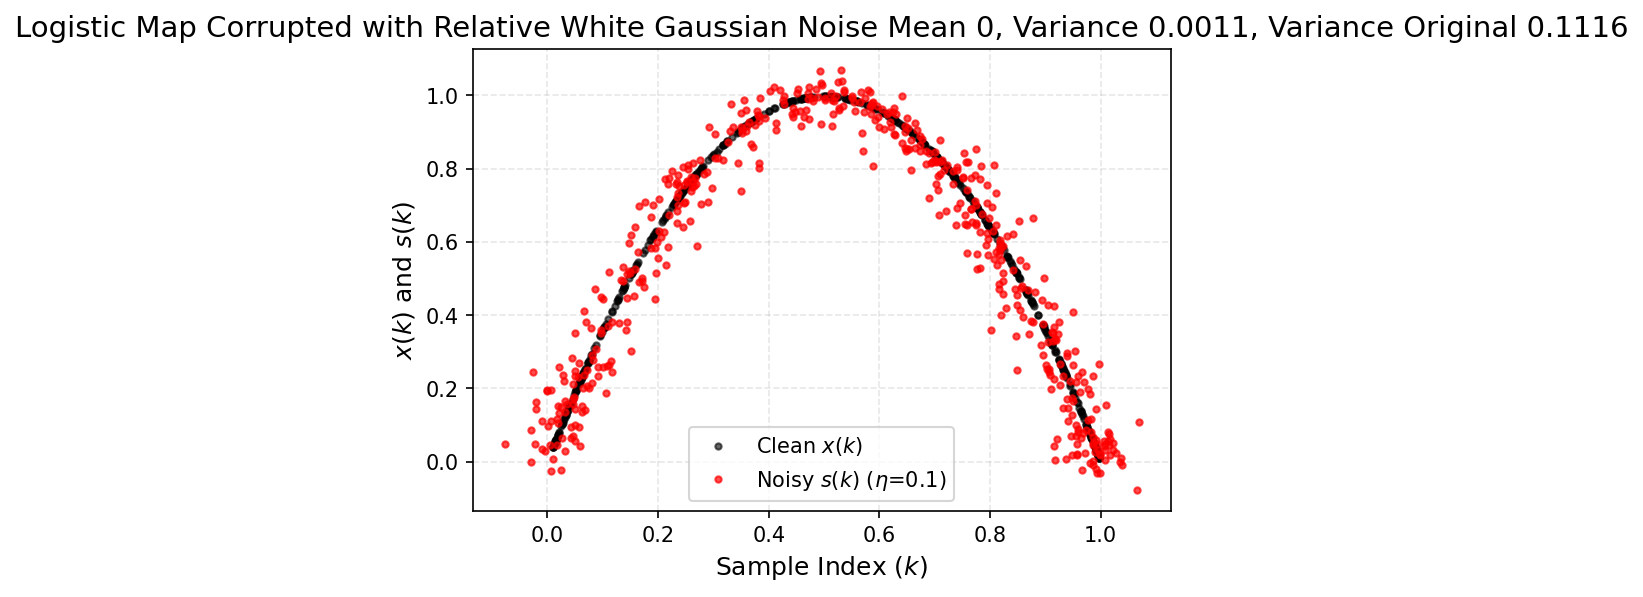

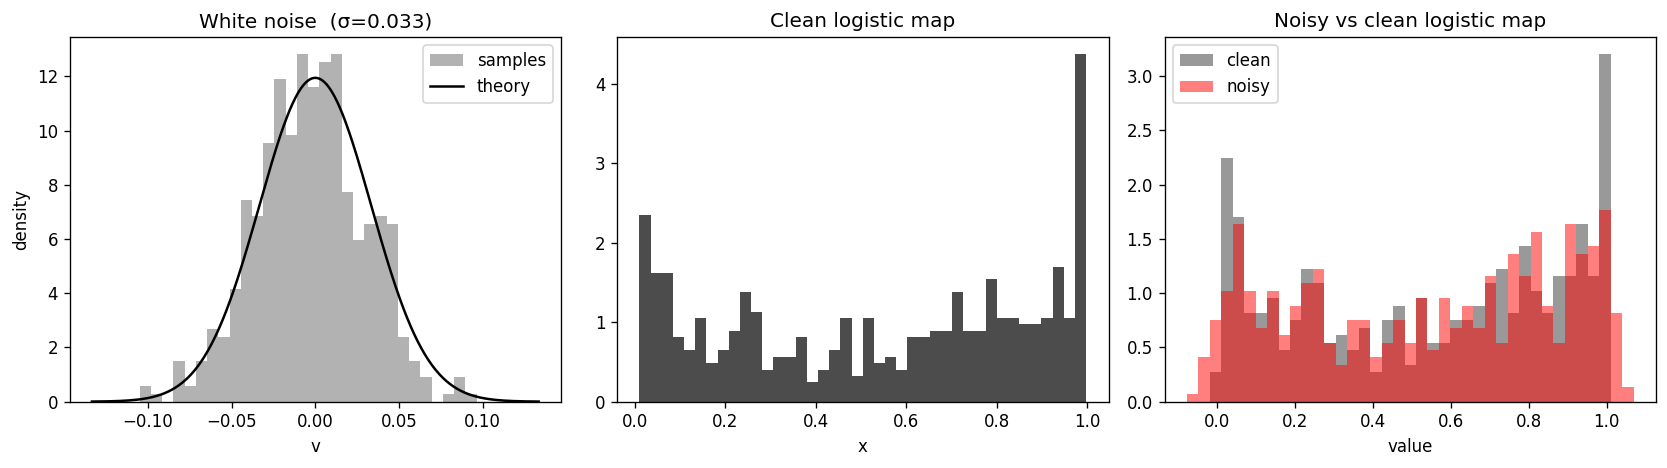

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Generate your clean logistic map time series (x_hist)
r = 3.99
x_current = 0.2
x_hist = []

for _ in range(200):  # Burn-in transients
  x_current = r * x_current * (1 - x_current)

for _ in range(500):  # Collect data
  x_next = r * x_current * (1 - x_current)
  x_hist.append(x_next)
  x_current = x_next

x_hist = np.array(x_hist)

# --- 2. Apply the Paper's Noise Formula ---
eta = 0.1  # 3% noise-to-signal ratio
sigma_x = np.std(x_hist)  # Standard deviation of the clean signal
sigma_noise = eta * sigma_x  # Scaled noise standard deviation
print(f" \nStandard Deviation Clean Signal {sigma_x :.3f}")
print(f"Standard Deviation Noisy Signal {sigma_noise :.3f}")
# Generate white noise using the paper's formula
white_noise = np.random.normal(loc=0.0, scale=sigma_noise, size=len(x_hist))

# Construct noisy time series s(k)
s_k = x_hist + white_noise
var_noise = sigma_noise**2


# --- 3. Quick Plot to Verify ---
plt.figure(figsize=(6, 4), dpi=150)
plt.plot(x_hist[:-1],x_hist[1:], '.',
         label="Clean $x(k)$", color="black", alpha=0.6)
plt.plot(s_k[:-1],s_k[1:],'.',
         label=f"Noisy $s(k)$ ($\eta$={eta})",color="red",lw=0.8,alpha=0.7,)
plt.title(
    f"Logistic Map Corrupted with Relative White Gaussian Noise Mean {0}, Variance {sigma_noise**2 :.4f}, Variance Original {sigma_x**2 :.4f}", fontsize=14
    )
plt.xlabel("Sample Index ($k$)", fontsize=12)
plt.ylabel("$x(k)$ and $s(k)$", fontsize=12)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.3)


#----------------------------#
fig, ax = plt.subplots(1, 3, figsize=(14, 4), dpi=120)

# (a) white noise, with theoretical N(0, sigma_noise^2)
t = np.linspace(-4 * sigma_noise, 4 * sigma_noise, 500)
pdf = np.exp(-t**2 / (2 * var_noise)) / np.sqrt(2 * np.pi * var_noise)
ax[0].hist(white_noise, bins=30, density=True, alpha=0.6, color="gray",
           label="samples")
ax[0].plot(t, pdf, "k", label="theory")
ax[0].set_title(f"White noise  (σ={sigma_noise:.3f})")
ax[0].set_xlabel("v")
ax[0].set_ylabel("density")
ax[0].legend()

# (b) original logistic map
ax[1].hist(x_hist, bins=40, density=True, alpha=0.7, color="black")
ax[1].set_title("Clean logistic map")
ax[1].set_xlabel("x")

# (c) noisy logistic map, clean one overlaid for comparison
bins = np.linspace(min(s_k.min(), x_hist.min()),
                   max(s_k.max(), x_hist.max()), 40)
ax[2].hist(x_hist, bins=bins, density=True, alpha=0.4, color="black",
           label="clean")
ax[2].hist(s_k, bins=bins, density=True, alpha=0.5, color="red",
           label="noisy")
ax[2].set_title("Noisy vs clean logistic map")
ax[2].set_xlabel("value")
ax[2].legend()

plt.tight_layout()
plt.show()